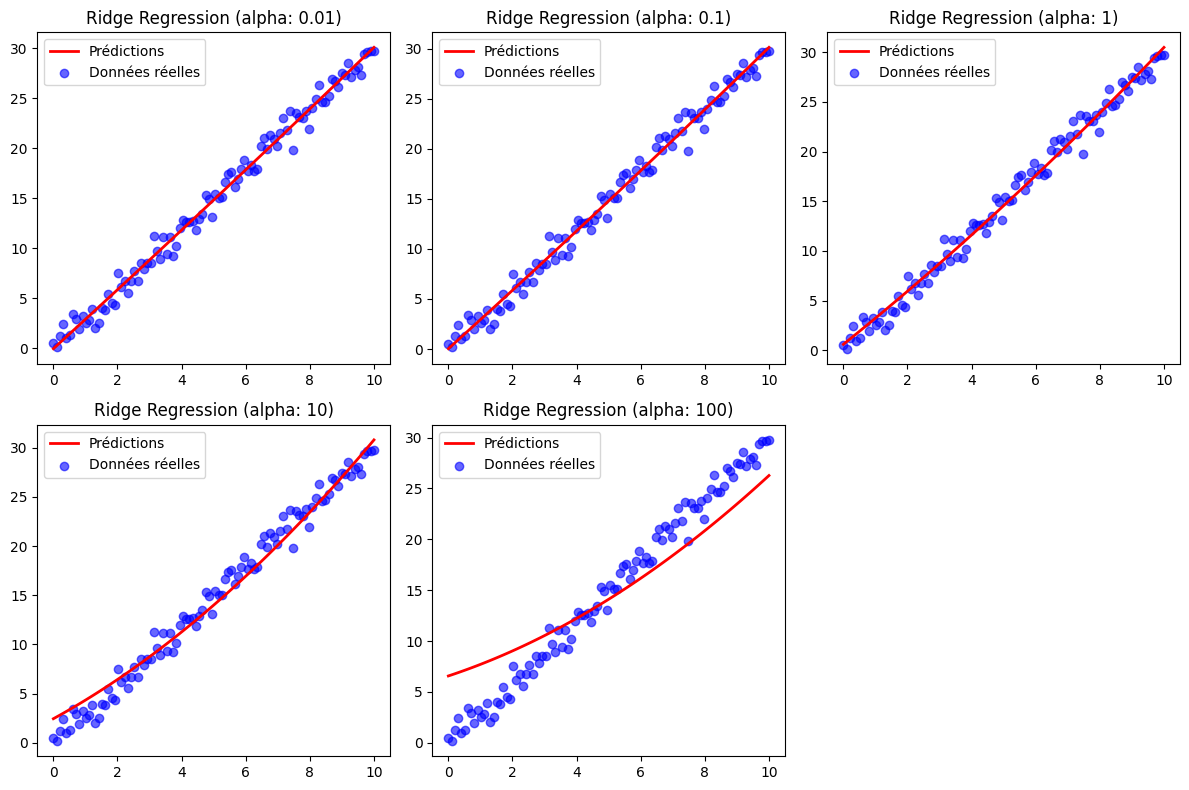

Résultats de la régression Ridge :
                RSS  Intercept    Coef_x  Coef_x_squared
0.01      81.180960  14.896153  8.560688        0.233524
0.10      81.283283  14.896153  8.446336        0.343855
1.00      87.666194  14.896153  7.565500        1.184688
10.00    163.412336  14.896153  5.205630        3.163682
100.00  1051.123583  14.896153  3.046468        2.784675


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler

# Fonction pour effectuer la régression Ridge
def ridge_regression(data, predictors, alpha, models_to_plot={}):
    """
    Effectue une régression Ridge, trace les résultats si spécifié, et retourne RSS et les coefficients.

    Paramètres :
        data (pd.DataFrame) : Les données contenant les prédicteurs et la variable cible.
        predictors (list) : Liste des colonnes utilisées comme prédicteurs.
        alpha (float) : Paramètre de régularisation Ridge.
        models_to_plot (dict) : Dictionnaire {alpha: subplot_index} pour tracer les prédictions.

    Retourne :
        list : [RSS, intercept, coefficients].
    """
    # Normaliser les prédicteurs
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(data[predictors])
    y = data['y']

    # Ajuster le modèle
    ridgereg = Ridge(alpha=alpha)
    ridgereg.fit(X_scaled, y)  # Optimise w pour minimiser (E)

    # Prédire les valeurs cibles
    y_pred = ridgereg.predict(X_scaled)

    # Tracer les résultats si alpha est dans models_to_plot
    if alpha in models_to_plot:
        plt.subplot(models_to_plot[alpha])
        plt.tight_layout()
        plt.plot(data['x'], y_pred, linewidth=2, color='red', label='Prédictions')
        plt.scatter(data['x'], data['y'], color='blue', alpha=0.6, label='Données réelles')
        plt.title(f'Ridge Regression (alpha: {alpha:.3g})')
        plt.legend()

    # Calculer le RSS (Residual Sum of Squares)
    rss = sum((y_pred - y) ** 2)

    # Retourner le RSS, l’interception et les coefficients
    ret = [rss]
    ret.append(ridgereg.intercept_)
    ret.extend(ridgereg.coef_)
    return ret

# Génération de données synthétiques pour l'exemple
np.random.seed(42)
x = np.linspace(0, 10, 100)
y = 3 * x + np.random.normal(0, 1, 100)  # y = 3x + bruit
data = pd.DataFrame({'x': x, 'y': y})

# Ajouter un prédicteur quadratique pour tester la régularisation
data['x_squared'] = data['x'] ** 2
predictors = ['x', 'x_squared']

# Visualiser plusieurs modèles avec différents alphas
alphas = [0.01, 0.1, 1, 10, 100]
models_to_plot = {0.01: 231, 0.1: 232, 1: 233, 10: 234, 100: 235}

plt.figure(figsize=(12, 8))

# Stocker les résultats pour chaque alpha
results = []
for alpha in alphas:
    result = ridge_regression(data, predictors, alpha, models_to_plot)
    results.append(result)

plt.tight_layout()
plt.show()

# Afficher les résultats finaux
columns = ['RSS', 'Intercept'] + [f'Coef_{pred}' for pred in predictors]
results_df = pd.DataFrame(results, columns=columns, index=alphas)
print("Résultats de la régression Ridge :")
print(results_df)


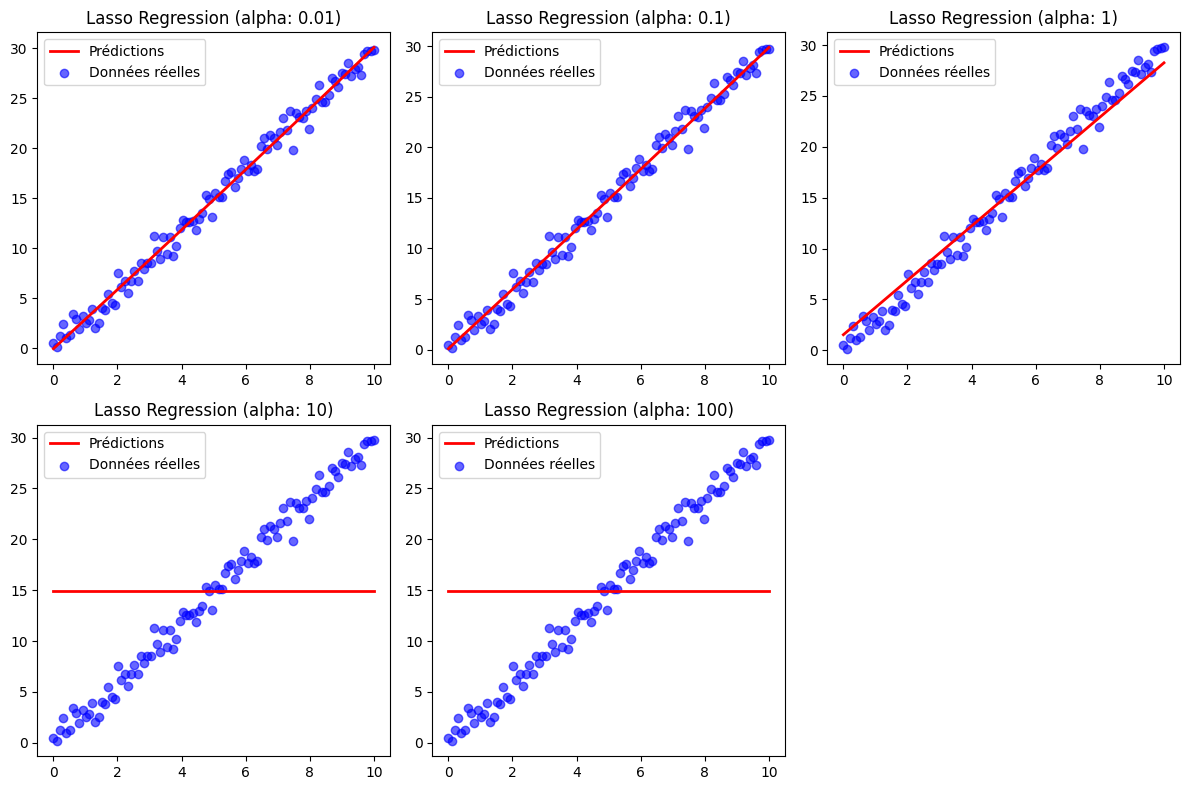

Résultats de la régression Lasso :
                RSS  Intercept    Coef_x  Coef_x_squared
0.01      81.190204  14.896153  8.581037        0.203856
0.10      82.189540  14.896153  8.534803        0.158594
1.00     181.490471  14.896153  7.787512        0.000000
10.00   7803.526967  14.896153  0.000000        0.000000
100.00  7803.526967  14.896153  0.000000        0.000000


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Lasso
from sklearn.preprocessing import StandardScaler

# Fonction pour effectuer la régression Lasso
def lasso_regression(data, predictors, alpha, models_to_plot={}):
    """
    Effectue une régression Lasso, trace les résultats si spécifié, et retourne RSS et les coefficients.

    Paramètres :
        data (pd.DataFrame) : Les données contenant les prédicteurs et la variable cible.
        predictors (list) : Liste des colonnes utilisées comme prédicteurs.
        alpha (float) : Paramètre de régularisation Lasso.
        models_to_plot (dict) : Dictionnaire {alpha: subplot_index} pour tracer les prédictions.

    Retourne :
        list : [RSS, intercept, coefficients].
    """
    # Normaliser les prédicteurs
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(data[predictors])
    y = data['y']

    # Ajuster le modèle
    lassoreg = Lasso(alpha=alpha, max_iter=10000)
    lassoreg.fit(X_scaled, y)  # Optimise w pour minimiser (E)

    # Prédire les valeurs cibles
    y_pred = lassoreg.predict(X_scaled)

    # Tracer les résultats si alpha est dans models_to_plot
    if alpha in models_to_plot:
        plt.subplot(models_to_plot[alpha])
        plt.tight_layout()
        plt.plot(data['x'], y_pred, linewidth=2, color='red', label='Prédictions')
        plt.scatter(data['x'], data['y'], color='blue', alpha=0.6, label='Données réelles')
        plt.title(f'Lasso Regression (alpha: {alpha:.3g})')
        plt.legend()

    # Calculer le RSS (Residual Sum of Squares)
    rss = sum((y_pred - y) ** 2)

    # Retourner le RSS, l’interception et les coefficients
    ret = [rss]
    ret.append(lassoreg.intercept_)
    ret.extend(lassoreg.coef_)
    return ret

# Génération de données synthétiques
np.random.seed(42)
x = np.linspace(0, 10, 100)
y = 3 * x + np.random.normal(0, 1, 100)  # y = 3x + bruit
data = pd.DataFrame({'x': x, 'y': y})

# Ajouter un prédicteur quadratique pour tester la régularisation
data['x_squared'] = data['x'] ** 2
predictors = ['x', 'x_squared']

# Visualiser plusieurs modèles avec différents alphas
alphas = [0.01, 0.1, 1, 10, 100]
models_to_plot = {0.01: 231, 0.1: 232, 1: 233, 10: 234, 100: 235}

plt.figure(figsize=(12, 8))

# Stocker les résultats pour chaque alpha
results = []
for alpha in alphas:
    result = lasso_regression(data, predictors, alpha, models_to_plot)
    results.append(result)

plt.tight_layout()
plt.show()

# Afficher les résultats finaux
columns = ['RSS', 'Intercept'] + [f'Coef_{pred}' for pred in predictors]
results_df = pd.DataFrame(results, columns=columns, index=alphas)
print("Résultats de la régression Lasso :")
print(results_df)


# PCA

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import yfinance as yf

 Définition des paramètres de l'analyse


In [ ]:
tickers = ['IBM', 'MSFT', 'META', 'T', 'INTC', 'GOLD', 'NEM', 'AU', 'AEM', 'GFI']
start = "2015-09-01"
end = "2016-11-01"
#tickers : Liste des actions sélectionnées pour le portefeuille , les symboles présentes des entreprise
#période d'analyse entre 2015 et 2016

 Téléchargement des données

In [ ]:
stock_data = yf.download(tickers, start=start, end=end)['Close']
print(stock_data)
#Télécharge les prix de clôture des actions à l'aide de yfinance et les stocké dans une data frame stock_data

[*********************100%***********************]  10 of 10 completed

Ticker            AEM         AU       GFI       GOLD         IBM       INTC  \
Date                                                                           
2015-09-01  20.412640   6.858500  2.415163   5.709921   90.664520  21.832750   
2015-09-02  19.981215   6.858500  2.294001   5.659166   92.170509  22.444876   
2015-09-03  19.279083   6.912574  2.310155   5.481524   93.269814  22.821575   
2015-09-04  19.295996   6.849487  2.334388   5.422309   91.312706  22.382093   
2015-09-08  19.169104   7.029737  2.310155   5.515362   93.555771  23.151186   
...               ...        ...       ...        ...         ...        ...   
2016-10-25  42.402317  12.464263  3.446532  14.380160   99.558899  28.439867   
2016-10-26  41.384796  12.175866  3.332192  14.175823  100.172592  28.294018   
2016-10-27  41.701172  12.040678  3.291357  14.346105  101.188736  28.204889   
2016-10-28  42.239857  12.184877  3.307691  14.541924  100.700470  28.148174   
2016-10-31  43.436935  12.383152  3.3893

Vérification et gestion des données manquantes

In [ ]:
print("Données manquantes par colonne :")
print(stock_data.isnull().sum())
stock_data = stock_data.dropna(axis=1, how='any')
#isnull().sum() pour afficher les éléments manquant et dropna(axis=1, how='any') pour les supprimé
#

Données manquantes par colonne :
Ticker
AEM     0
AU      0
GFI     0
GOLD    0
IBM     0
INTC    0
META    0
MSFT    0
NEM     0
T       0
dtype: int64


Calcul des rendements quotidiens

In [ ]:
portfolio_returns = stock_data.pct_change().dropna()
#les rendement sont calculé avec pct.change()
print(portfolio_returns)

Ticker           AEM        AU       GFI      GOLD       IBM      INTC  \
Date                                                                     
2015-09-02 -0.021135  0.000000 -0.050167 -0.008889  0.016611  0.028037   
2015-09-03 -0.035140  0.007884  0.007042 -0.031390  0.011927  0.016783   
2015-09-04  0.000877 -0.009126  0.010490 -0.010803 -0.020983 -0.019257   
2015-09-08 -0.006576  0.026316 -0.010381  0.017161  0.024565  0.034362   
2015-09-09 -0.048985 -0.037179 -0.016451 -0.038344 -0.014807 -0.008814   
...              ...       ...       ...       ...       ...       ...   
2016-10-25  0.026921  0.023686  0.036855  0.021779  0.002058 -0.004538   
2016-10-26 -0.023997 -0.023138 -0.033175 -0.014210  0.006164 -0.005128   
2016-10-27  0.007645 -0.011103 -0.012255  0.012012  0.010144 -0.003150   
2016-10-28  0.012918  0.011976  0.004963  0.013650 -0.004825 -0.002011   
2016-10-31  0.028340  0.016272  0.024691  0.029859  0.007077  0.003742   

Ticker          META      MSFT       

Standardisation des données

In [ ]:
scaler = StandardScaler()
standardized_returns = scaler.fit_transform(portfolio_returns)
#La PCA nécessite des données normalisées. StandardScaler transforme les données pour qu'elles aient une moyenne de 0 et un écart-type de 1.

Application de l'analyse en composantes principales (PCA)

In [ ]:
pca = PCA()
pca_components = pca.fit_transform(standardized_returns)
#La PCA transforme les données normalisées en composantes principales, qui sont des combinaisons linéaires des variables originales.
#Résultat : pca_components contient les données projetées dans le nouvel espace des composantes principales.

Variance expliquée par les composantes principales

In [ ]:
explained_variance_ratio = pca.explained_variance_ratio_
print("Variance expliquée par chaque composante :", explained_variance_ratio)
#explained_variance_ratio_ représente la proportion de la variance totale expliquée par chaque composante principa
#Ces valeurs permettent de déterminer le nombre de composantes nécessaires pour capturer l’essentiel de l’information dans les données.


Variance expliquée par chaque composante : [0.42121288 0.26869094 0.08533359 0.05978372 0.05009234 0.03747204
 0.03397908 0.01924378 0.01391685 0.01027478]


Visualisation de la variance expliquée cumulative

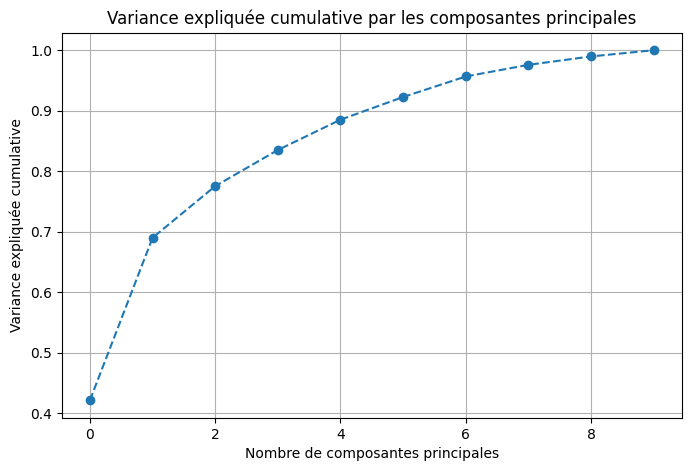

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(np.cumsum(explained_variance_ratio), marker='o', linestyle='--')
plt.title('Variance expliquée cumulative par les composantes principales')
plt.xlabel('Nombre de composantes principales')
plt.ylabel('Variance expliquée cumulative')
plt.grid()
plt.show()
#Affiche la somme cumulée de la variance expliquée pour chaque composante.
#Permet de choisir le nombre optimal de composantes pour capturer la majeure partie de la variance.

Visualisation des deux premières composantes principales

<ipython-input-20-ab355be941c9>:2: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = plt.cm.get_cmap('tab10', len(tickers))  # Générer une palette de couleurs


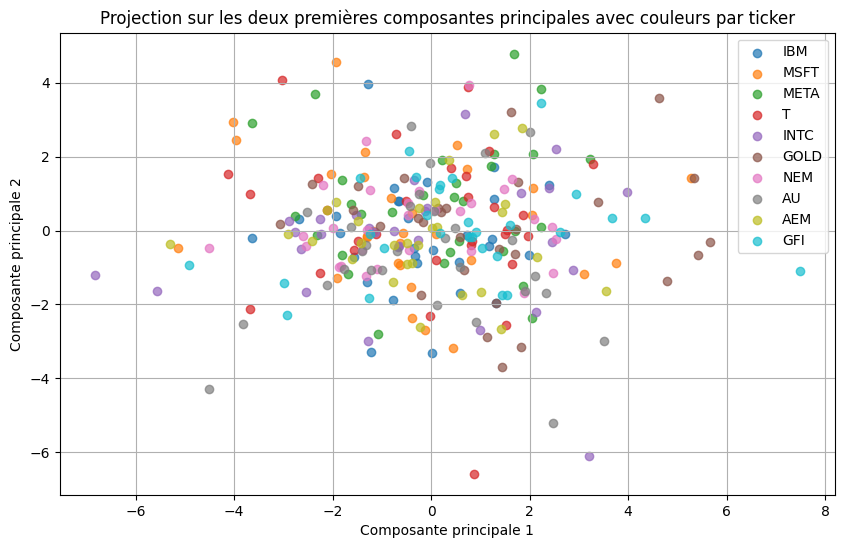

In [ ]:
classes = np.tile(range(len(tickers)), (portfolio_returns.shape[0] // len(tickers) + 1))[:portfolio_returns.shape[0]]  # Associer chaque point à un ticker
colors = plt.cm.get_cmap('tab10', len(tickers))  # Générer une palette de couleurs

plt.figure(figsize=(10, 6))
for i, ticker in enumerate(tickers):
    points = pca_components[classes == i]  # Points associés à chaque ticker
    plt.scatter(points[:, 0], points[:, 1], label=ticker, color=colors(i), alpha=0.7)

plt.title('Projection sur les deux premières composantes principales avec couleurs par ticker')
plt.xlabel('Composante principale 1')
plt.ylabel('Composante principale 2')
plt.legend(loc='best')
plt.grid()
plt.show()

#Projette les données sur les deux premières composantes principales (PC1) et PC2
#Visualise les relations entre les observations dans l’espace des composantes principales.

# Comparaison Ridge et Lasso

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge, Lasso
from sklearn.preprocessing import StandardScaler
#importation des bibliothèques

Génération des données synthétiques

In [ ]:
np.random.seed(42)
x = np.linspace(0, 10, 100)
y = 3 * x + np.random.normal(0, 1, 100)  # y = 3x + bruit
data = pd.DataFrame({'x': x, 'y': y})
#x est une variable indépendante avec 100 points entre 0 et 10.
#y est la variable dépendante, définie par y=3x+bruit
# où le bruit est aléatoire (distribution normale centrée en 0, écart-type de 1).
#DataFrame data : Contient deux colonnes, x et y.

Ajout d'un prédicteur quadratique

In [ ]:
data['x_squared'] = data['x'] ** 2
predictors = ['x', 'x_squared']
#une colonne x_squared pour capturer des relations quadratiques dans les données.
#predictors est une liste des colonnes utilisées comme variables explicatives dans les modèles.

Standardisation des données

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(data[predictors])
y = data['y']
#a régularisation Ridge et Lasso dépend des magnitudes des prédicteurs. Standardiser garantit que toutes les variables sont sur la même échelle.

Génération des valeurs de 𝜆


In [ ]:
alphas = np.logspace(-3, 2, 100)
#alphas : Génère 100 valeurs de  logarithmiquement espacées entre 10^-3 et 10^2
#λ contrôle l'intensité de la régularisation :

Stockage des coefficients Ridge et Lasso

 Calcul des coefficients pour chaque 𝜆


In [ ]:

# Stocker les coefficients pour Ridge et Lasso
ridge_coefs = []
lasso_coefs = []

for alpha in alphas:
    # Régression Ridge
    ridge = Ridge(alpha=alpha)
    ridge.fit(X_scaled, y)
    ridge_coefs.append(ridge.coef_)

    # Régression Lasso
    lasso = Lasso(alpha=alpha, max_iter=10000)
    lasso.fit(X_scaled, y)
    lasso_coefs.append(lasso.coef_)

ridge_coefs = np.array(ridge_coefs)
lasso_coefs = np.array(lasso_coefs)


Conversion en matrices NumPy

In [ ]:
ridge_coefs = np.array(ridge_coefs)
lasso_coefs = np.array(lasso_coefs)
#c'est juste pour facilité la manipulation

Visualisation des coefficients
Ridge

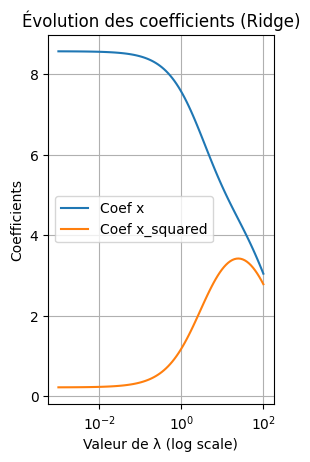

In [ ]:
plt.subplot(1, 2, 1)
for i, coef in enumerate(ridge_coefs.T):
    plt.plot(alphas, coef, label=f'Coef {predictors[i]}')
plt.xscale('log')
plt.title('Évolution des coefficients (Ridge)')
plt.xlabel('Valeur de λ (log scale)')
plt.ylabel('Coefficients')
plt.legend()
plt.grid()


Visualisation des coefficients
Lasso

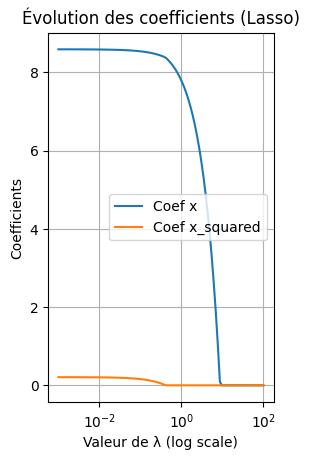

In [ ]:
plt.subplot(1, 2, 2)
for i, coef in enumerate(lasso_coefs.T):
    plt.plot(alphas, coef, label=f'Coef {predictors[i]}')
plt.xscale('log')
plt.title('Évolution des coefficients (Lasso)')
plt.xlabel('Valeur de λ (log scale)')
plt.ylabel('Coefficients')
plt.legend()
plt.grid()



# Question Bonus

Importation des Bibliothèques

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import ElasticNet
from sklearn.preprocessing import StandardScaler


Génération des données synthétiques

In [ ]:
np.random.seed(42)
x = np.linspace(0, 10, 100)
y = 3 * x + np.random.normal(0, 1, 100)
data = pd.DataFrame({'x': x, 'y': y})
data['x_squared'] = data['x'] ** 2
predictors = ['x', 'x_squared']
# x  Une variable indépendante, allant de 0 à 10 (100 points).

Standardisation des prédicteurs

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(data[predictors])
y = data['y']
#ourquoi standardiser ?
#La régularisation L1 et L2 est sensible à l'échelle des variables.
#StandardScaler transforme les prédicteurs pour avoir une moyenne de 0 et un écart-type de 1.

Définir les hyperparamètres

In [ ]:
alphas = [0.1, 1, 10]
l1_ratios = [0.1, 0.5, 0.9]


Création et entraînement des modèles ElasticNet

In [ ]:
for i, alpha in enumerate(alphas):
    for j, l1_ratio in enumerate(l1_ratios):
        model = ElasticNet(alpha=alpha, l1_ratio=l1_ratio, random_state=42)
        model.fit(X_scaled, y)
        y_pred = model.predict(X_scaled)
# La combainison de L1 et L2

Visualisation des résultats

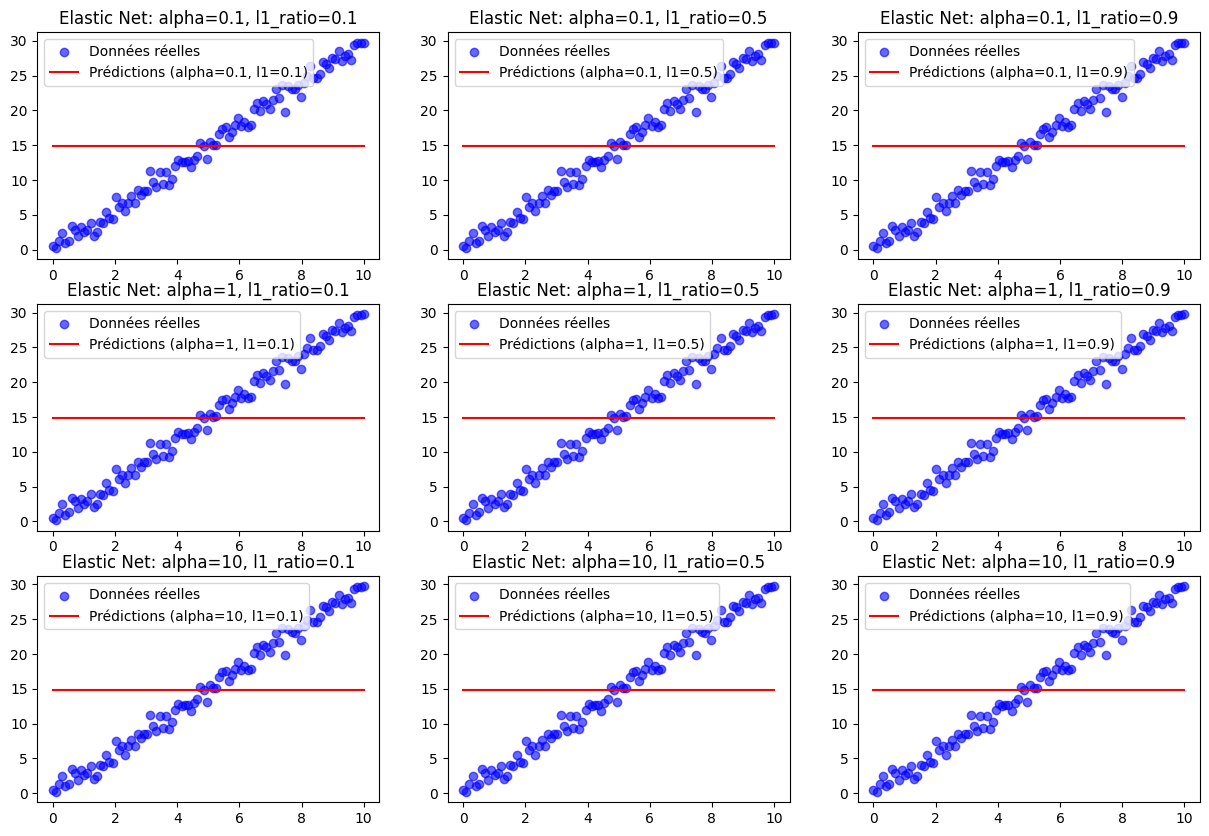

In [ ]:
plt.figure(figsize=(15, 10))

for i, alpha in enumerate(alphas):
    for j, l1_ratio in enumerate(l1_ratios):
        # Tracer les résultats
        plt.subplot(len(alphas), len(l1_ratios), i * len(l1_ratios) + j + 1)
        plt.scatter(data['x'], y, color='blue', alpha=0.6, label='Données réelles')
        plt.plot(data['x'], y_pred, color='red', label=f'Prédictions (alpha={alpha}, l1={l1_ratio})')
        plt.title(f'Elastic Net: alpha={alpha}, l1_ratio={l1_ratio}')
        plt.legend()
